STUDENT PERFORMANCE PREDICTION

In [1]:
# inspecting the dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("student_performance.csv")
df.head()
df.info()
df.shape
df.describe(include='all')




<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 6 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   student_id               1000000 non-null  int64  
 1   weekly_self_study_hours  1000000 non-null  float64
 2   attendance_percentage    1000000 non-null  float64
 3   class_participation      1000000 non-null  float64
 4   total_score              1000000 non-null  float64
 5   grade                    1000000 non-null  str    
dtypes: float64(4), int64(1), str(1)
memory usage: 45.8 MB


,student_id,weekly_self_study_hours,attendance_percentage,class_participation,total_score,grade
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000
unique,NaN,NaN,NaN,NaN,NaN,5
top,NaN,NaN,NaN,NaN,NaN,A
freq,NaN,NaN,NaN,NaN,NaN,548644
mean,500000.500000,15.029127,84.711046,5.985203,84.283845,NaN
std,288675.278932,6.899431,9.424143,1.956421,15.432969,NaN
min,1.000000,0.000000,50.000000,0.000000,9.400000,NaN
25%,250000.750000,10.300000,78.300000,4.700000,73.900000,NaN
50%,500000.500000,15.000000,85.000000,6.000000,87.500000,NaN
75%,750000.250000,19.700000,91.800000,7.300000,100.000000,NaN


In [2]:
# finding missing values
df.isnull().sum()
# check duplicated values
df.duplicated().sum()

# check unique values in categorical columns
df["grade"].unique()

# count students in each grade 
df["grade"].value_counts()
df["student_id"].duplicated().sum()


np.int64(0)

# AFTER WALKING THROUGH THE DATASET I FOUND OUT THAT THERE WERE NO MISSING OR DUPLICATED VALUES.

In [3]:
# Identifying the numerical and categorical columns 

numerical_columns=df.select_dtypes(
    include=np.number
).columns

print(numerical_columns)

categorical_columns=df.select_dtypes(
    include="object"
).columns

print(categorical_columns)


Index(['student_id', 'weekly_self_study_hours', 'attendance_percentage',
       'class_participation', 'total_score'],
      dtype='str')
Index(['grade'], dtype='str')


C:\Users\DELL\AppData\Local\Temp\ipykernel_8244\1322881023.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns=df.select_dtypes(


# PERFORMING EDA
EDA- Exploratory Data Analysis-understand the characteristcs of the data 

We have 3 types of EDA
1. Unvariate analysis - one variable
2. Bivariate analysis - between two variables
3. Multivariate analysis - among multiple variables



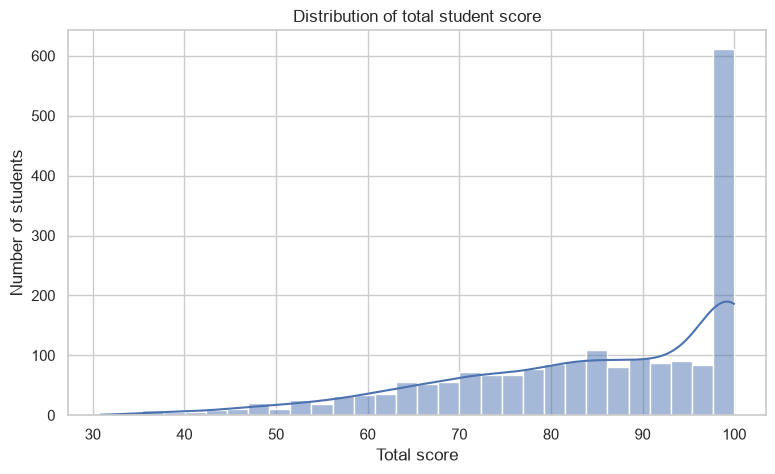

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
# we'll use sample for certain visualizations to keep plotting responsive

sns.set_theme(style="whitegrid")
plot_df=df.sample(
    n=min(2000,len(df)),
    random_state=42
)

# HISTOGRAM: Distribution of total scores
# numerical columns
plt.figure(figsize=(9,5))
sns.histplot(
    data=plot_df,
    x="total_score",
    bins=30,
    kde=True

)

plt.title("Distribution of total student score")
plt.xlabel("Total score")
plt.ylabel("Number of students")
plt.show()


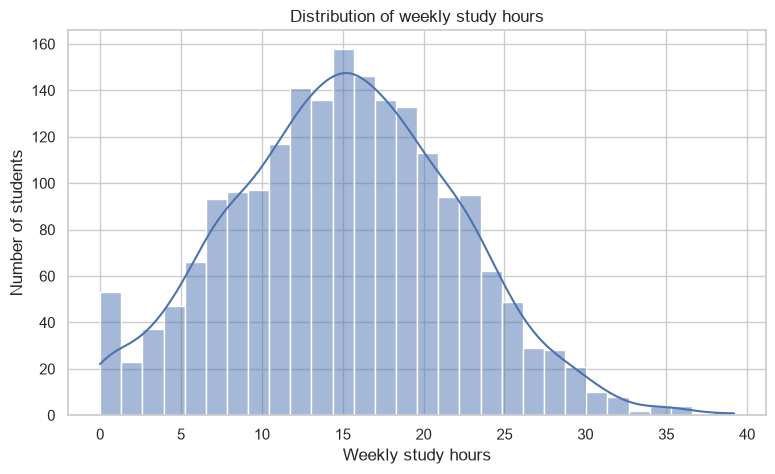

In [5]:
# histogram of weekly-study hours
plt.figure(figsize=(9,5))
sns.histplot(
    data=plot_df,
    x="weekly_self_study_hours",
    bins=30,
    kde=True
)
plt.title("Distribution of weekly study hours")
plt.xlabel("Weekly study hours")
plt.ylabel("Number of students")
plt.show()



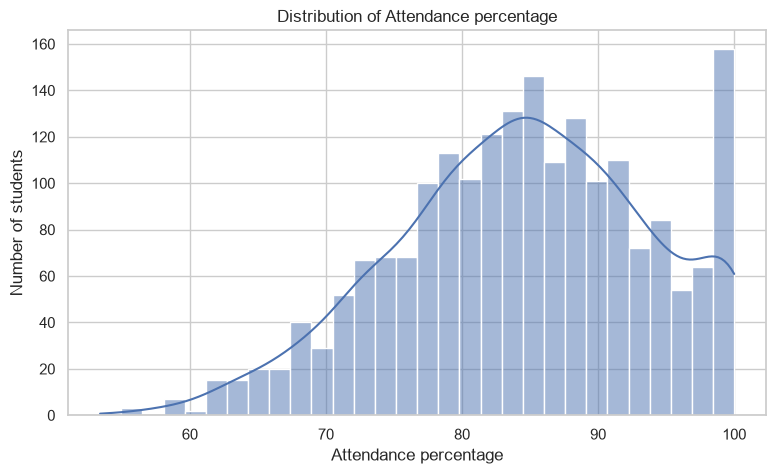

In [6]:
# calculating the attedance percentage
plt.figure(figsize=(9,5))
sns.histplot(
    data=plot_df,
    x="attendance_percentage",
    bins=30,
    kde=True
)
plt.title("Distribution of Attendance percentage")
plt.xlabel("Attendance percentage")
plt.ylabel("Number of students")
plt.show()


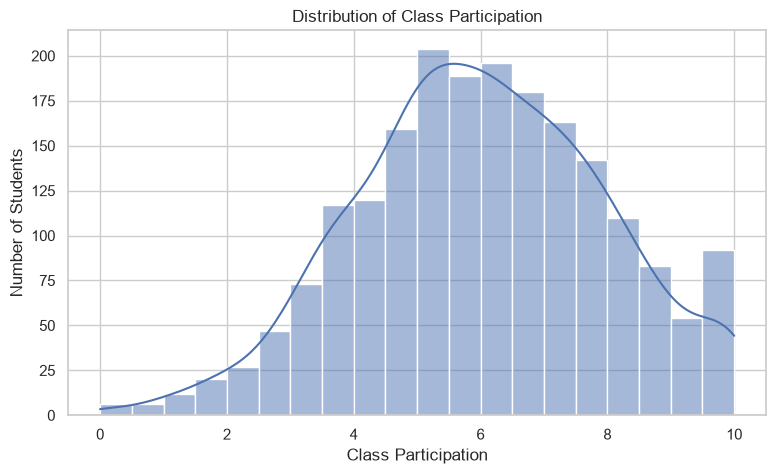

In [7]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=plot_df,
    x="class_participation",
    bins=20,
    kde=True
)

plt.title("Distribution of Class Participation")
plt.xlabel("Class Participation")
plt.ylabel("Number of Students")

plt.show()

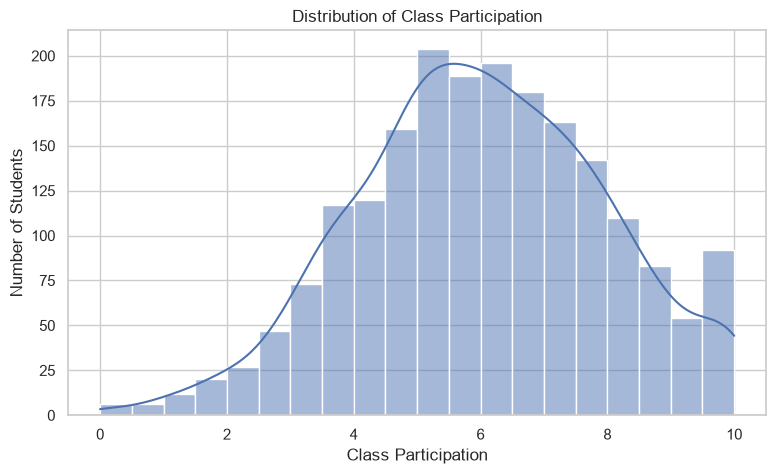

In [8]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=plot_df,
    x="class_participation",
    bins=20,
    kde=True
)

plt.title("Distribution of Class Participation")
plt.xlabel("Class Participation")
plt.ylabel("Number of Students")

plt.show()

# BIVARIATE ANALYSIS - RELATIONSHIP BETWEEN TWO VARIABLES

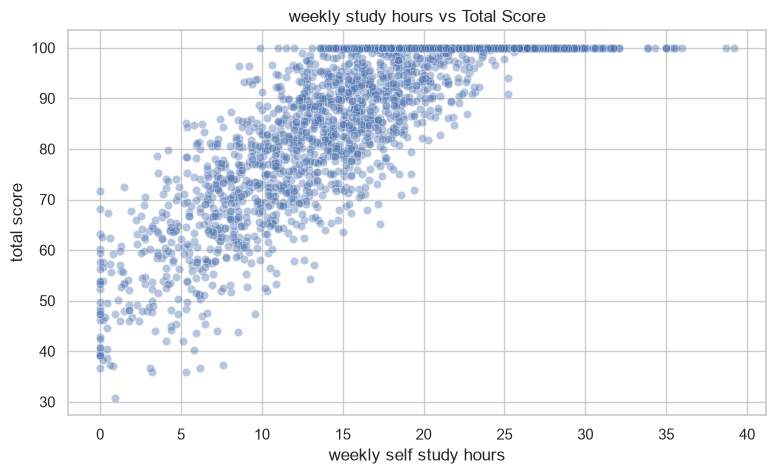

In [9]:
#  Study hours vs total score
# Do students who study more tend to score higher
plt.figure(figsize=(9,5))
sns.scatterplot(
    data=plot_df,
    x="weekly_self_study_hours",
    y="total_score",
    alpha=0.4
)

plt.title("weekly study hours vs Total Score")
plt.xlabel("weekly self study hours")
plt.ylabel("total score")

plt.show()



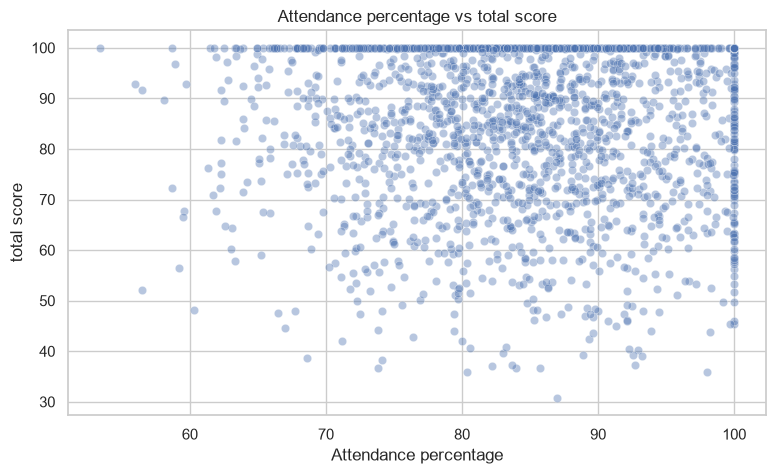

In [10]:
# attendance vs total score 
plt.figure(figsize=(9,5))

sns.scatterplot(
    data=plot_df,
    x="attendance_percentage",
    y="total_score",
    alpha=0.4
)

plt.title("Attendance percentage vs total score")
plt.xlabel("Attendance percentage")
plt.ylabel("total score")

plt.show()


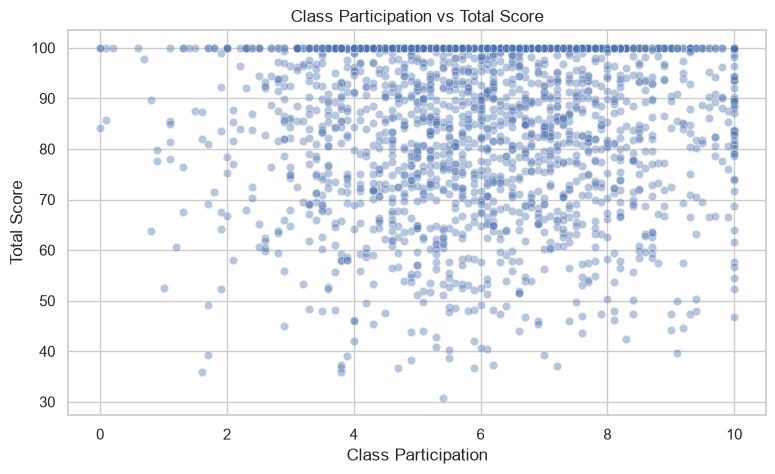

In [11]:
# class participation vs total score
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=plot_df,
    x="class_participation",
    y="total_score",
    alpha=0.4
)

plt.title("Class Participation vs Total Score")
plt.xlabel("Class Participation")
plt.ylabel("Total Score")

plt.show()

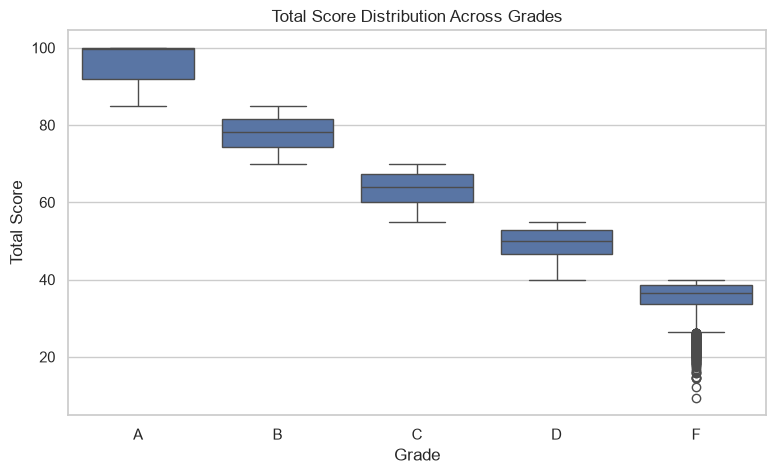

In [12]:
# Box plot : Grade vs total score
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="grade",
    y="total_score",
    order=["A", "B", "C", "D", "F"]
)

plt.title("Total Score Distribution Across Grades")
plt.xlabel("Grade")
plt.ylabel("Total Score")

plt.show()

# MULTIVARIATE ANALYSIS
Correlation

In [13]:
correlation_matrix = df[
    [
        "weekly_self_study_hours",
        "attendance_percentage",
        "class_participation",
        "total_score"
    ]
].corr()

print(correlation_matrix)

                         weekly_self_study_hours  attendance_percentage  \
weekly_self_study_hours                 1.000000              -0.001008   
attendance_percentage                  -0.001008               1.000000   
class_participation                     0.001244              -0.000043   
total_score                             0.812241              -0.001014   

                         class_participation  total_score  
weekly_self_study_hours             0.001244     0.812241  
attendance_percentage              -0.000043    -0.001014  
class_participation                 1.000000     0.000684  
total_score                         0.000684     1.000000  


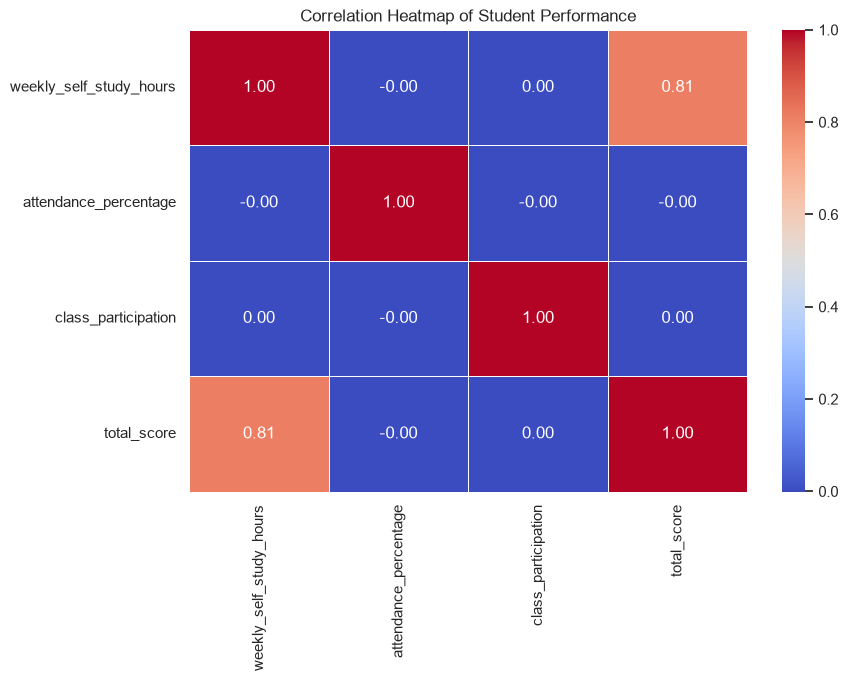

In [14]:
# visualize using a heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Student Performance")

plt.show()



# Advanced EDA
Part1: Outlier detection

In [15]:
numerical_features = [
    "weekly_self_study_hours",
    "attendance_percentage",
    "class_participation",
    "total_score"
]

for column in numerical_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nFeature: {column}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outliers:", len(outliers))


Feature: weekly_self_study_hours
Lower Bound: -3.799999999999997
Upper Bound: 33.8
Outliers: 3541

Feature: attendance_percentage
Lower Bound: 58.05
Upper Bound: 112.05
Outliers: 3518

Feature: class_participation
Lower Bound: 0.8000000000000007
Upper Bound: 11.2
Outliers: 4927

Feature: total_score
Lower Bound: 34.750000000000014
Upper Bound: 139.14999999999998
Outliers: 2027


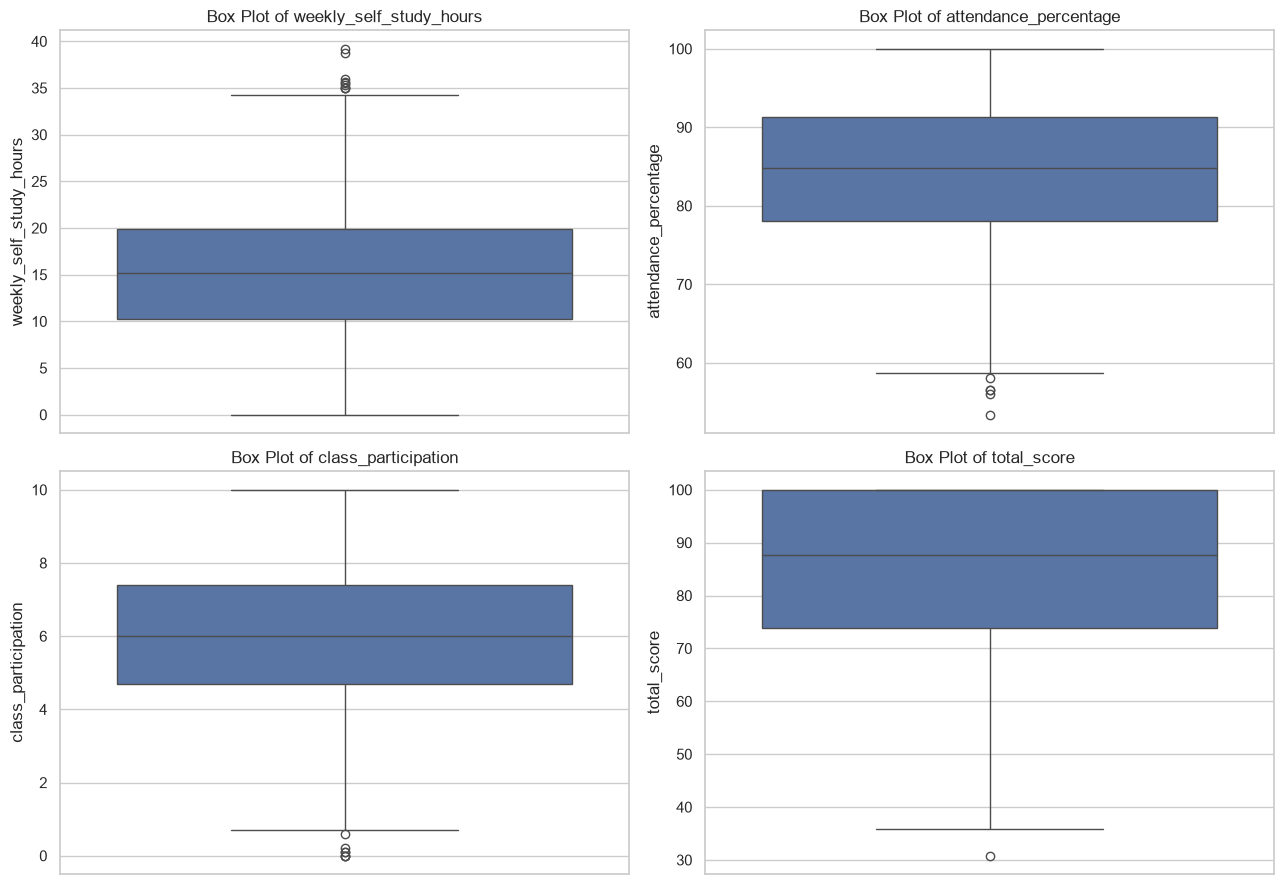

In [16]:
# visualize potential outliers using box plot
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

features = [
    "weekly_self_study_hours",
    "attendance_percentage",
    "class_participation",
    "total_score"
]

for column, ax in zip(features, axes.flatten()):

    sns.boxplot(
        data=plot_df,
        y=column,
        ax=ax
    )

    ax.set_title(f"Box Plot of {column}")

plt.tight_layout()
plt.show()

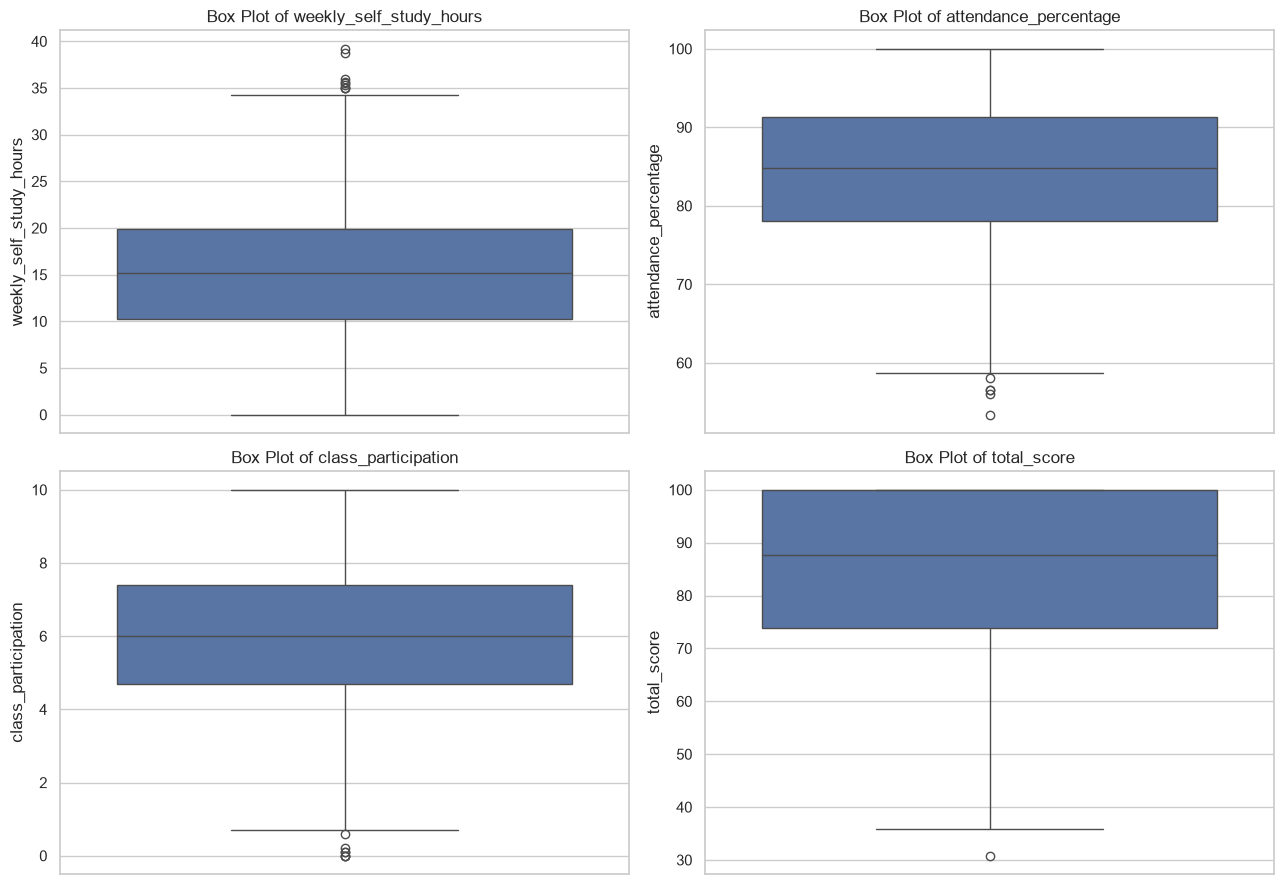

In [17]:
# inverstigate the relationshi between grade and total score
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

features = [
    "weekly_self_study_hours",
    "attendance_percentage",
    "class_participation",
    "total_score"
]

for column, ax in zip(features, axes.flatten()):

    sns.boxplot(
        data=plot_df,
        y=column,
        ax=ax
    )

    ax.set_title(f"Box Plot of {column}")

plt.tight_layout()
plt.show()

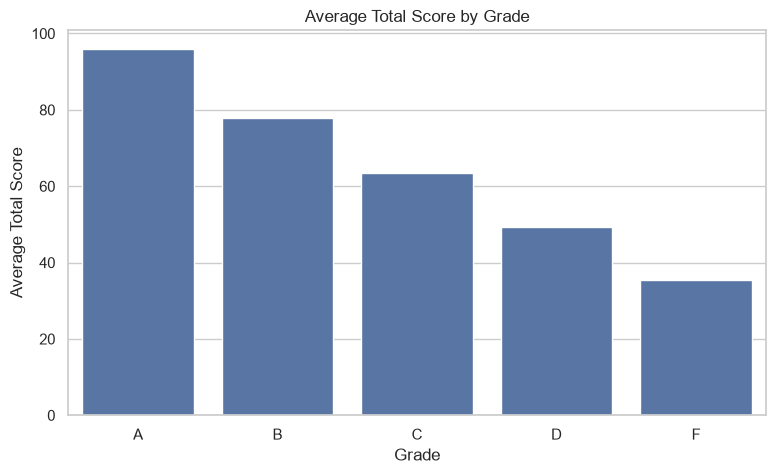

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="grade",
    y="total_score",
    order=["A", "B", "C", "D", "F"],
    errorbar=None
)

plt.title("Average Total Score by Grade")
plt.xlabel("Grade")
plt.ylabel("Average Total Score")

plt.show()

In [19]:
model_df = df[
    [
        "weekly_self_study_hours",
        "attendance_percentage",
        "class_participation",
        "grade"
    ]
].copy()


In [20]:
# FEATURE ENGINEERING 
# daily study hours 
model_df["daily_self_study_hours"] = (
    model_df["weekly_self_study_hours"] / 7
)

model_df[
    [
        "weekly_self_study_hours",
        "daily_self_study_hours"
    ]
].head()



,weekly_self_study_hours,daily_self_study_hours
0,18.5,2.642857
1,14.0,2.000000
2,19.5,2.785714
3,25.7,3.671429
4,13.4,1.914286


In [21]:
model_df["study_intensity"] = pd.cut(
    model_df["weekly_self_study_hours"],
    bins=[-0.01, 10, 20, 40],
    labels=["Low", "Moderate", "High"]
)

In [22]:
model_df["study_intensity"].value_counts()

study_intensity
Moderate    524329
Low         240675
High        234996
Name: count, dtype: int64

In [23]:
model_df["study_intensity"].value_counts(
    normalize=True
) * 100

study_intensity
Moderate    52.4329
Low         24.0675
High        23.4996
Name: proportion, dtype: float64

In [25]:
# attendance category 
model_df["attendance_category"] = pd.cut(
    model_df["attendance_percentage"],
    bins=[49.99, 70, 85, 100],
    labels=["Low", "Moderate", "High"]
)

model_df["attendance_category"].value_counts()


attendance_category
High        498435
Moderate    434075
Low          67490
Name: count, dtype: int64

In [26]:
# study attendance interactions 
model_df["study_attendance_interaction"] = (
    model_df["weekly_self_study_hours"] *
    model_df["attendance_percentage"] / 100
)


In [27]:
model_df.head(10)


,weekly_self_study_hours,attendance_percentage,class_participation,grade,daily_self_study_hours,study_intensity,attendance_category,study_attendance_interaction
0,18.5,95.6,3.8,A,2.642857,Moderate,High,17.6860
1,14.0,80.0,2.5,B,2.000000,Moderate,Moderate,11.2000
2,19.5,86.3,5.3,A,2.785714,Moderate,High,16.8285
3,25.7,70.2,7.0,A,3.671429,High,Moderate,18.0414
4,13.4,81.9,6.9,A,1.914286,Moderate,Moderate,10.9746
5,13.4,65.1,5.0,A,1.914286,Moderate,Low,8.7234
6,26.1,81.8,5.9,A,3.728571,High,Moderate,21.3498
7,20.4,100.0,4.0,A,2.914286,High,High,20.4000
8,11.7,100.0,8.2,C,1.671429,Moderate,High,11.7000
9,18.8,67.6,6.0,B,2.685714,Moderate,Low,12.7088


In [30]:
# eda in the new features 
model_df.isnull().sum()
model_df.shape



(1000000, 8)

In [31]:
# we check the target variable 
model_df["grade"].value_counts()

grade
A    548644
B    258174
C    141980
D     44998
F      6204
Name: count, dtype: int64

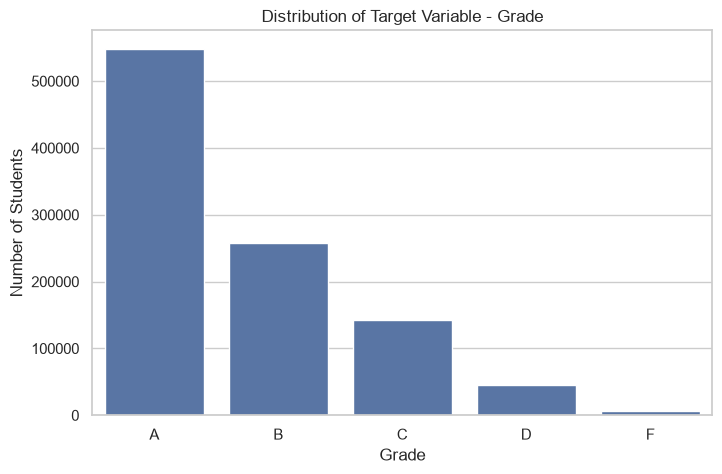

In [32]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=model_df,
    x="grade",
    order=["A", "B", "C", "D", "F"]
)

plt.title("Distribution of Target Variable - Grade")
plt.xlabel("Grade")
plt.ylabel("Number of Students")

plt.show()

In [34]:
# splitting into training and test dataset
X = model_df[
    [
        "weekly_self_study_hours",
        "attendance_percentage",
        "class_participation"
    ]
]

y = model_df["grade"]
# as the target variable is imbalanced so we need stratified 
# test split 

print("Features shape:", X.shape)
print("Target shape:", y.shape)



Features shape: (1000000, 3)
Target shape: (1000000,)


In [38]:
model_df.to_csv(
    "student_performance.csv",
    index=False
)


In [41]:
model_df.to_csv(
    "..feature_engineered_dataset.csv",
    index=False
)

In [39]:
final_dataset = model_df[
    [
        "weekly_self_study_hours",
        "attendance_percentage",
        "class_participation",
        "grade"
    ]
].copy()

final_dataset.to_csv(
    "..final_ml_dataset.csv",
    index=False
)

In [43]:
from sklearn.model_selection import train_test_split

X = model_df[
    [
        "weekly_self_study_hours",
        "attendance_percentage",
        "class_participation"
    ]
]

y = model_df["grade"]

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [45]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training features: (800000, 3)
Testing features: (200000, 3)

Training target distribution:
grade
A    54.864375
B    25.817375
C    14.198000
D     4.499875
F     0.620375
Name: proportion, dtype: float64

Testing target distribution:
grade
A    54.8645
B    25.8175
C    14.1980
D     4.4995
F     0.6205
Name: proportion, dtype: float64


In [46]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

print("Baseline Accuracy:",
      accuracy_score(y_test, dummy_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dummy_predictions,
    zero_division=0
))

Baseline Accuracy: 0.548645

Classification Report:
              precision    recall  f1-score   support

           A       0.55      1.00      0.71    109729
           B       0.00      0.00      0.00     51635
           C       0.00      0.00      0.00     28396
           D       0.00      0.00      0.00      8999
           F       0.00      0.00      0.00      1241

    accuracy                           0.55    200000
   macro avg       0.11      0.20      0.14    200000
weighted avg       0.30      0.55      0.39    200000



# We will use Logistic Regression for the classification 

In [47]:
# IMPROVED ML MODEL 
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions
logistic_predictions = logistic_model.predict(X_test)

# Evaluate
print("Accuracy:",
      accuracy_score(y_test, logistic_predictions))

print("Macro F1:",
      f1_score(y_test, logistic_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))



Accuracy: 0.695755
Macro F1: 0.4496233853828942

Classification Report:
              precision    recall  f1-score   support

           A       0.83      0.88      0.85    109729
           B       0.51      0.51      0.51     51635
           C       0.51      0.45      0.48     28396
           D       0.50      0.34      0.40      8999
           F       0.00      0.00      0.00      1241

    accuracy                           0.70    200000
   macro avg       0.47      0.44      0.45    200000
weighted avg       0.68      0.70      0.69    200000



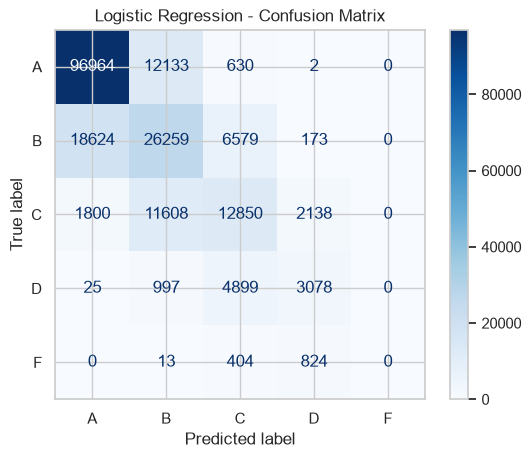

In [48]:
# plotting confusion matrix to find why model is making mistakes

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    logistic_predictions,
    labels=["A", "B", "C", "D", "F"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["A", "B", "C", "D", "F"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [49]:
weighted_logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train
weighted_logistic_model.fit(X_train, y_train)

# Predict
weighted_predictions = weighted_logistic_model.predict(X_test)

# Evaluate
print("Accuracy:",
      accuracy_score(y_test, weighted_predictions))

print("Macro F1:",
      f1_score(y_test, weighted_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    weighted_predictions,
    zero_division=0
))

Accuracy: 0.64425
Macro F1: 0.45350957052018764

Classification Report:
              precision    recall  f1-score   support

           A       0.89      0.78      0.83    109729
           B       0.48      0.54      0.51     51635
           C       0.42      0.42      0.42     28396
           D       0.27      0.33      0.30      8999
           F       0.12      0.72      0.21      1241

    accuracy                           0.64    200000
   macro avg       0.44      0.56      0.45    200000
weighted avg       0.69      0.64      0.66    200000



For grade F:
- Recall = 0.72: The model catches approximately 72% of actual F students.
- Precision = 0.12: Only 12% of students predicted as F actually belong to F.
This tells us that the weighted model is identifying more struggling students, but it is also incorrectly flagging many students from other grades.

Also notice that macro F1 increased from 0.4496 to 0.4535. That's a small improvement, not a dramatic one. We'll need to compare more models before deciding.

# DECISION TREE CLASSIFIER

In [50]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

decision_tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

# Train
decision_tree_model.fit(X_train, y_train)

# Predict
tree_predictions = decision_tree_model.predict(X_test)

# Evaluate
print("Accuracy:",
      accuracy_score(y_test, tree_predictions))

print("Macro F1:",
      f1_score(y_test, tree_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    tree_predictions,
    zero_division=0
))

Accuracy: 0.600635
Macro F1: 0.4016779458818028

Classification Report:
              precision    recall  f1-score   support

           A       0.80      0.77      0.79    109729
           B       0.40      0.42      0.41     51635
           C       0.36      0.37      0.37     28396
           D       0.30      0.32      0.31      8999
           F       0.12      0.15      0.13      1241

    accuracy                           0.60    200000
   macro avg       0.40      0.41      0.40    200000
weighted avg       0.61      0.60      0.60    200000



In [51]:
# RANDOM FOREST CLASSIFIER
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Train
random_forest_model.fit(X_train, y_train)

# Predict
rf_predictions = random_forest_model.predict(X_test)

# Evaluate
print("Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Macro F1:",
      f1_score(y_test, rf_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

Accuracy: 0.639415
Macro F1: 0.46585389122737497

Classification Report:
              precision    recall  f1-score   support

           A       0.91      0.74      0.82    109729
           B       0.47      0.58      0.51     51635
           C       0.43      0.42      0.42     28396
           D       0.30      0.44      0.36      8999
           F       0.14      0.55      0.22      1241

    accuracy                           0.64    200000
   macro avg       0.45      0.54      0.47    200000
weighted avg       0.69      0.64      0.66    200000



# why did Random Forest outperform a single Decision Tree?

A single Decision Tree depends on one set of learned splitting rules. It can be sensitive to the training data.

Random Forest builds many trees using different samples and feature subsets, then combines their predictions.

This often reduces variance and improves generalization compared with one tree.

                   Feature  Importance
0  weekly_self_study_hours    0.869002
1    attendance_percentage    0.076562
2      class_participation    0.054436


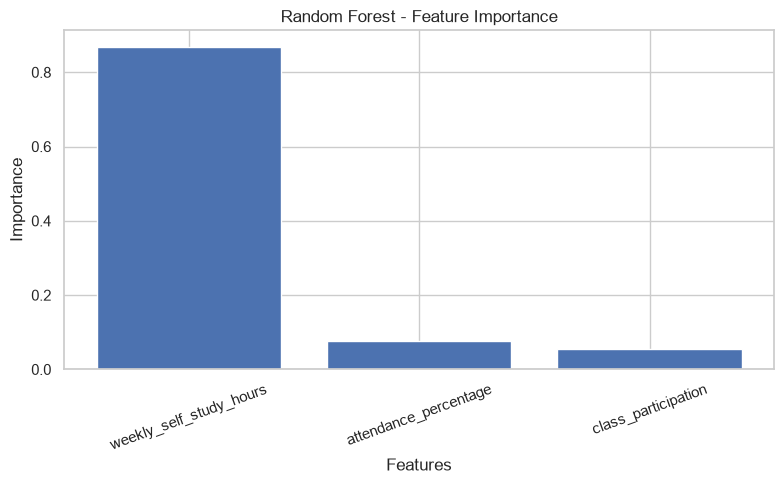

In [52]:
# FEATURE IMPORTANCE 
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()